# Лабораторна робота №2

**Інтелектуальний аналіз даних та моделювання кризових явищ**  
Токарчук Роман, група 507.

**Тема:** обробка англомовних текстів, TF-IDF і косинусна схожість.

Умови п’яти завдань збережені нижче. Реалізації — у [lab2.py](lab2.py), приклади запуску, матриці та графіки — у цьому ноутбуці. Код і результати першої лабораторної зберігаються окремо.

### Дані та запуск

В умові зазначено `resources/data.json`, але його немає ані в репозиторії лабораторних, ані в навчальному репозиторії на перевірених комітах. Тому в цей JSON без змін експортовано три тексти зі списку `documents` у [лекції 106-nlp.ipynb](https://github.com/maxvonlancaster/intelligent-data-analysis/blob/4cc5a33cd4606849cb999925db8c6252b9151d31/src/106-nlp.ipynb), комірка `f82b0058`. Це не відсутній оригінальний файл: це явно задокументована підготовка вхідного JSON з матеріалів викладача. Перші два тексти — про Inception, третій — про лінійну алгебру.

Для завдання 5 окремо підготовлено вісім власних коротких англомовних текстів на різні теми. Їх повний вміст збережено у `resources/lab2_own_texts.json`. Джерело та SHA-256 обох файлів: `resources/lab2_sources.json`.

Встановлення: `python -m pip install -r requirements.txt`. Відкрити ноутбук у Jupyter або VS Code та виконати **Run All** з кореня репозиторію. Після встановлення залежностей інтернет не потрібен. Стемер і орфографічний словник розраховані на англійську мову.

In [1]:
import json
import numpy as np
import pandas as pd
from IPython.display import display, Image
from lab2 import (ROOT, OUTPUTS, extract_texts_from_file, process_texts,
                  process_texts_with_audit, tfidf_features, calcuate_tfidf,
                  visualize_data, get_texts, analyse_corpus, main)

print("Робочий каталог:", ROOT.name)

Робочий каталог: ida-labs


## Extract data from the json file

Write a script, that would extract all the the data from the json file and return it in a list of texts for further use in the next tasks

### Реалізація

`extract_texts_from_file()` читає UTF-8 JSON і повертає список рядків. Підтримуються список `[...]` та об’єкт з полем `texts`. Кількість і порядок документів зберігаються; метадані не потрапляють у корпус. Некоректний JSON, відсутній файл або елементи неправильного типу спричиняють помилку. **Корпус** — це набір документів, які аналізуються разом.

In [2]:
texts = extract_texts_from_file("resources/data.json")
print("Документів:", len(texts))
for i, text in enumerate(texts, 1):
    print(f"D{i}: {text}")
assert len(texts) == 3

Документів: 3
D1: In Inception, the plot unfolds with thrilling action, keeping audiences on edge through a series of intense and unexpected twists.
D2: The story of Inception keeps audiences hooked with its thrilling action and surprising twists, making every moment unforgettable.
D3: The Matrix transformation preserves the vector's direction, illustrating how linear combinations affect the overall system.


## Process the texts

Write a script, that would process these texts. Processing should include:

- Lowercasing
- Removing Punctuation
- Removing Special Characters and Numbers
- Stemming or Lemmatization
- Handling Abbreviations
- Spelling Correction

### Реалізація

Обробка у `process_texts()` виконується в такому порядку:

1. Переведення в нижній регістр.
2. Розкриття скорочень за словником: `NLP → natural language processing`, `ML → machine learning`, `AI → artificial intelligence`, `pls → please` тощо. Заміна виконується по цілих словах до видалення пунктуації, щоб розпізнати `e.g.` та апострофи.
3. Виділення послідовностей англійських літер регулярним виразом `[a-z]+`. Пунктуація, цифри та спеціальні символи вилучаються; слова через дефіс розділяються.
4. Виправлення невідомих слів через **pyspellchecker** з відстанню редагування 1. Наприклад, перестановка літер у `langauge` дає `language`. Відомі технічні назви та `Inception` додано до захищеного словника.
5. Видалення англійських стоп-слів; заперечення `not`, `no`, `never`, `nor`, `cannot` збережено.
6. **Стемінг** PorterStemmer із NLTK: `running → run`, `processing → process`. Стем може не бути словниковим словом — це нормально для такого представлення.

Орфографія виправляється **до стемінгу**, бо результат стемінгу часто відсутній у словнику. Виправлення не розуміє контекст, тому всі фактичні заміни збережено для перевірки. Збереження заперечень саме по собі не додає моделі розуміння їхнього значення.

In [3]:
texts_processed, audit = process_texts_with_audit(texts)
display(pd.DataFrame({"Документ": [f"D{i}" for i in range(1, len(texts)+1)],
                      "До обробки": texts, "Після обробки": texts_processed}))
print("Фактичні орфографічні заміни:")
for row in audit:
    print(f"D{row["document"]}:", row["spelling_corrections"])

,Документ,До обробки,Після обробки
0,D1,"In Inception, the plot unfolds with thrilling ...",incept plot unfold thrill action keep audienc ...
1,D2,The story of Inception keeps audiences hooked ...,stori incept keep audienc hook thrill action s...
2,D3,The Matrix transformation preserves the vector...,matrix transform preserv vector direct illustr...


Фактичні орфографічні заміни:
D1: {}
D2: {}
D3: {}


### Окрема демонстрація скорочень та орфографії

У текстах лекції ці операції можуть нічого не змінити, тому нижче — явно створений тестовий рядок. Він не додається до корпусу й не впливає на матрицю схожості.

In [4]:
sample = "NLP and ML: langauge processing, running!!! 123 @#$"
sample_processed, sample_audit = process_texts_with_audit([sample])
print("Початковий текст:", sample)
print("Розкриті скорочення:", sample_audit[0]["expanded"])
print("Виправлення:", sample_audit[0]["spelling_corrections"])
print("Результат:", sample_processed[0])
assert sample_audit[0]["spelling_corrections"]["langauge"] == "language"

Початковий текст: NLP and ML: langauge processing, running!!! 123 @#$
Розкриті скорочення: natural language processing and machine learning: langauge processing, running!!! 123 @#$
Виправлення: {'langauge': 'language'}
Результат: natur languag process machin learn languag process run


## Calculate cosine similarities using TFIDF

Calculate the TFIDF score and cosine similarity between the texts. You may use gensim, write your own script using numpy or use other module. Output the result as a matrix $n\times n$  of cosine similarity scores (where $n$ is the length of texts list).

Extra credit: use word2vec word embeddings in vector spaces to get better TFIDF scores by representing each word as a vector.

### Реалізація і формули

`TfidfVectorizer` представляє корпус матрицею **документи × терміни**. TF — кількість входжень терміна в документ, IDF — вага терміна залежно від кількості документів, у яких він трапляється. Використано згладжену формулу scikit-learn:

$$\mathrm{idf}(t)=\ln\frac{1+n}{1+\mathrm{df}(t)}+1,$$

де $n$ — число документів, $\mathrm{df}(t)$ — число документів зі словом $t$. Ваги $\mathrm{tf}(t,d)\cdot\mathrm{idf}(t)$ нормуються так, щоб L2-норма кожного непорожнього рядка дорівнювала 1.

Косинусна схожість:

$$\mathrm{cos}(a,b)=\frac{a\cdot b}{\|a\|_2\|b\|_2}.$$

Для нормованих рядків це скалярний добуток. Функція `calcuate_tfidf()` повертає список списків розміру $n\times n$. Написання її назви збережено з шаблону викладача. Значення невід’ємні: 0 — немає спільних термінів у цьому представленні, 1 — однаковий напрямок векторів. Це оцінка лексичної схожості, а не ймовірність і не відсоток однакового змісту.

Якщо окремий документ стає порожнім, його вектор і схожість дорівнюють нулю, включно з діагоналлю. Якщо порожній весь корпус, функція повідомляє про відсутність словника. Для непорожніх документів діагональ дорівнює 1. Матриця симетрична.


In [5]:
vectorizer, X = tfidf_features(texts_processed)
print("Форма матриці TF-IDF:", X.shape)
display(pd.DataFrame(X.toarray(), index=["D1", "D2", "D3"],
                     columns=vectorizer.get_feature_names_out()).round(3))
cosine_matrix = calcuate_tfidf(texts_processed)
display(pd.DataFrame(cosine_matrix, index=["D1", "D2", "D3"], columns=["D1", "D2", "D3"]).round(4))
np.testing.assert_allclose(X.toarray() @ X.toarray().T, cosine_matrix, atol=1e-12)
np.testing.assert_allclose(np.diag(cosine_matrix), 1, atol=1e-12)

Форма матриці TF-IDF:

(3, 28)


,action,affect,audienc,combin,direct,edg,hook,illustr,incept,intens,...,seri,stori,surpris,thrill,transform,twist,unexpect,unfold,unforgett,vector
D1,0.247,0.000,0.247,0.000,0.000,0.325,0.000,0.000,0.247,0.325,...,0.325,0.000,0.000,0.247,0.000,0.247,0.325,0.325,0.000,0.000
D2,0.247,0.000,0.247,0.000,0.000,0.000,0.325,0.000,0.247,0.000,...,0.000,0.325,0.325,0.247,0.000,0.247,0.000,0.000,0.325,0.000
D3,0.000,0.316,0.000,0.316,0.316,0.000,0.000,0.316,0.000,0.000,...,0.000,0.000,0.000,0.000,0.316,0.000,0.000,0.000,0.000,0.316


,D1,D2,D3
D1,1.0000,0.3664,0.0
D2,0.3664,1.0000,0.0
D3,0.0000,0.0000,1.0


## Visualize data

Visualize the cosine_matrix data using matplotlib. Choose your own method of plotting the scores in a way, that the similarity indeces between texts would be instantly visible. Plot data about texts as well (a couple of first words in the document).

*Hint: remember heat maps, aren't they nice for this task?*

### Реалізація

У `visualize_data()` через Matplotlib побудовано **теплову карту**. Колір кодує схожість у фіксованій шкалі 0–1, а в кожній клітинці є числове значення. Підписи містять ID документа і перші чотири слова після обробки. Оригінальні тексти наведено вище, тому кожен ID можна зіставити з повним документом. Графік зберігається в `figures/lab2/lecture_cosine.png`.

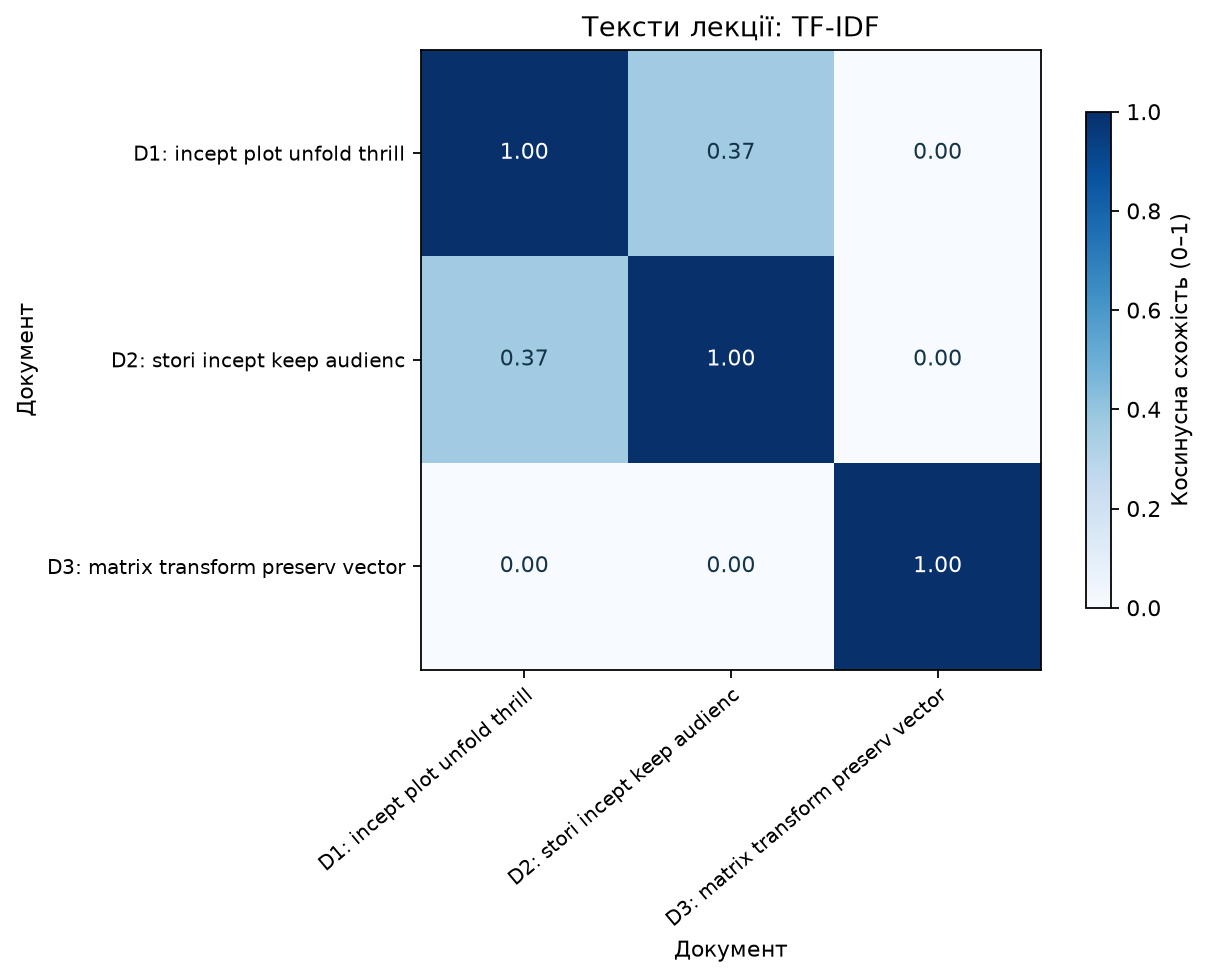

,document,terms
0,D1,"edg, intens, plot, seri, unexpect"
1,D2,"hook, make, moment, stori, surpris"
2,D3,"affect, combin, direct, illustr, linear"


Найбільш схожа пара: {'document_1': 'D1', 'document_2': 'D2', 'cosine': 0.36644681626651315}


In [6]:
lecture_result = analyse_corpus(texts, "lecture")
display(Image(filename=str(lecture_result["image"])))
display(pd.DataFrame(lecture_result["top_terms"]))
print("Найбільш схожа пара:", lecture_result["pairs"][0])
assert lecture_result["cosine"][0, 1] > lecture_result["cosine"][0, 2]

### Інтерпретація

D1 і D2 описують той самий фільм та мають спільні терміни про глядачів, дію й сюжетні повороти. D3 містить терміни лінійної алгебри, тому має меншу схожість із кінорецензіями. Назва `Matrix` у цьому реченні означає матрицю: TF-IDF не визначає значення слова з контексту. Графік показує відмінність словника, а не автоматичне розуміння теми.

## Analyse your own text using TFIDF (or any other method)

Analyse your own text using previous methods. You may use API fetching to get text data, download texts from Kaggle or use any texts you want. Find cosine similarities and visualize them

Recommendation: use sentence_transform / openai embedding model

### Власний корпус

Вісім оригінальних коротких англомовних текстів збережено у `resources/lab2_own_texts.json`. Теми: обробка мови, машинне навчання, повені, харчування та баскетбол. Серед них є тематично близькі пари й окремі теми. Це підготовлені приклади для аналізу текстів, а не повідомлення про реальні події.

`get_texts()` читає цей набір. Далі повторно застосовано той самий ланцюжок: очищення → TF-IDF → косинусна схожість → теплова карта. Векторизатор навчається окремо на цьому корпусі, тому значення двох матриць не слід прямо порівнювати як оцінки в одному просторі.

В умові дозволено TF-IDF або інший метод. Для обов’язкових пунктів використано TF-IDF; рекомендація sentence-transformers/OpenAI та додатковий Word2Vec не реалізовувалися.

D1: NLP systems process human language. A Python program cleans text, corrects spelling, and represents documents as vectors. Cosine similarity compares these document vectors.
D2: Natural language processing in Python starts with text cleaning. We correct spelling, remove punctuation, and build document vectors to calculate cosine similarity between texts.
D3: An ML model learns patterns from training data. A programmer uses Python to split the dataset into training and validation subsets and measure prediction errors.
D4: Machine learning uses training data to learn patterns. Validation data measures prediction errors and helps compare models before evaluating a separate test dataset.
D5: Heavy rain can cause a river flood. Emergency teams monitor rainfall, river levels, and flood forecasts to warn people living near the river.
D6: A river flood warning depends on rainfall and rising river levels. Emergency teams use weather forecasts to prepare evacuation routes before heavy rain ar

,Документ,Оброблений текст
0,D1,natur languag process system process human lan...
1,D2,natur languag process python start text clean ...
2,D3,machin learn model learn pattern train data pr...
3,D4,machin learn use train data learn pattern vali...
4,D5,heavi rain caus river flood emerg team monitor...
5,D6,river flood warn depend rainfal rise river lev...
6,D7,healthi diet includ veget fruit bean grain coo...
7,D8,basketbal player practic pass shoot defend tea...


,D1,D2,D3,D4,D5,D6,D7,D8
D1,1.000,0.649,0.028,0.037,0.000,0.000,0.000,0.000
D2,0.649,1.000,0.033,0.000,0.000,0.000,0.000,0.000
D3,0.028,0.033,1.000,0.716,0.000,0.032,0.000,0.000
D4,0.037,0.000,0.716,1.000,0.000,0.031,0.042,0.000
D5,0.000,0.000,0.000,0.000,1.000,0.621,0.040,0.030
D6,0.000,0.000,0.032,0.031,0.621,1.000,0.000,0.033
D7,0.000,0.000,0.000,0.042,0.040,0.000,1.000,0.000
D8,0.000,0.000,0.000,0.000,0.030,0.033,0.000,1.000


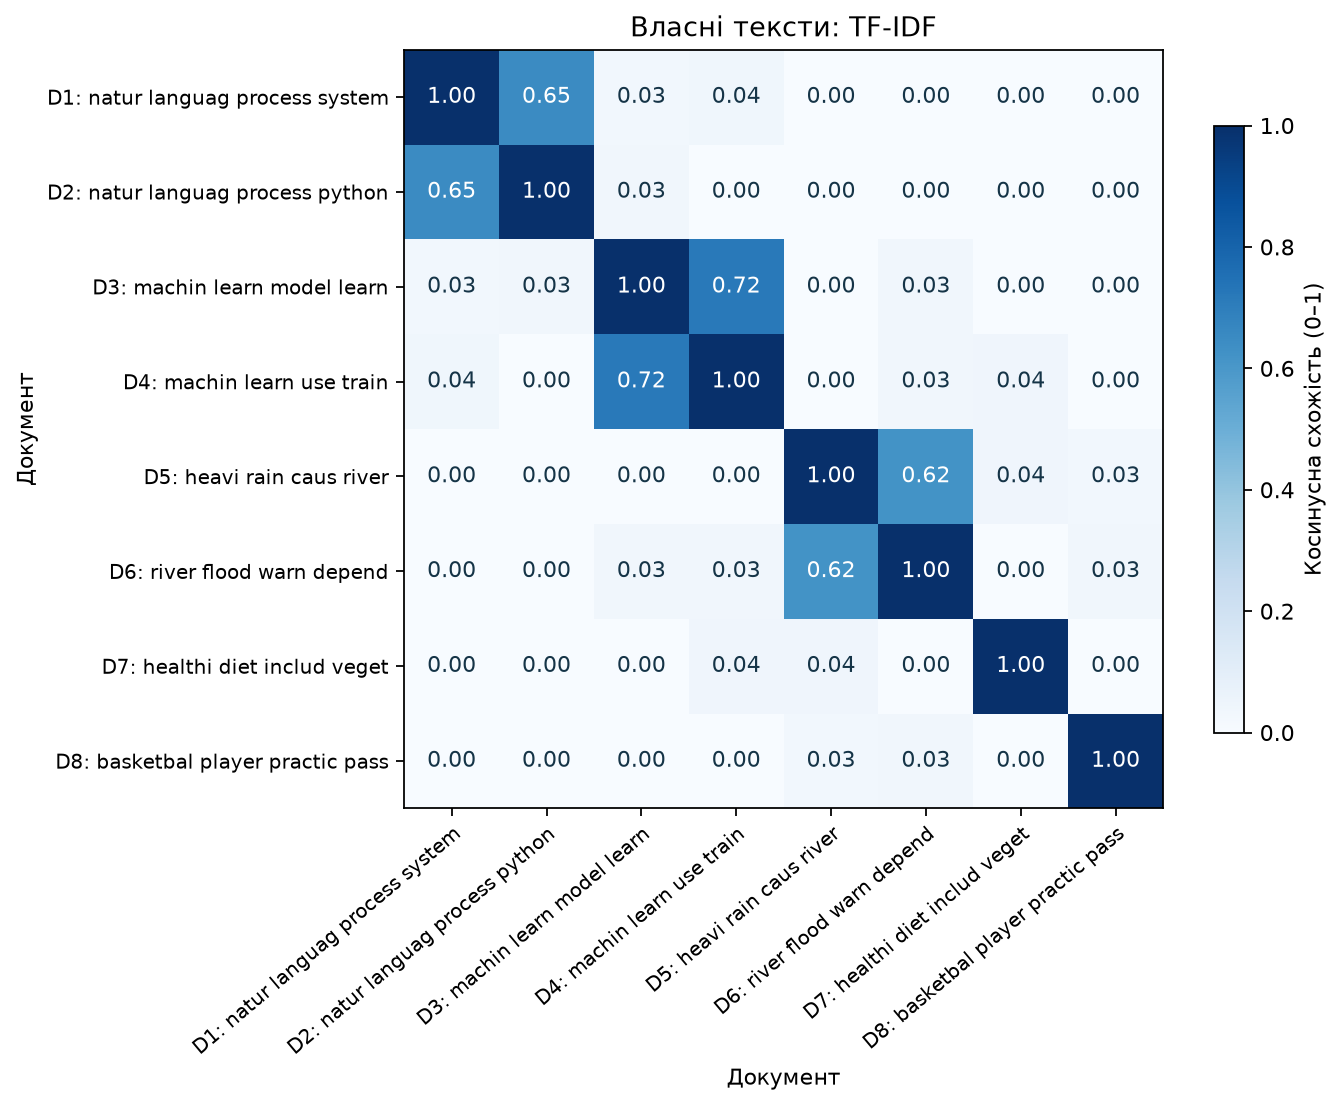

In [7]:
own_texts = get_texts()
for i, text in enumerate(own_texts, 1):
    print(f"D{i}: {text}")
own_result = analyse_corpus(own_texts, "own")
display(pd.DataFrame({"Документ": [f"D{i}" for i in range(1, len(own_texts)+1)],
                      "Оброблений текст": own_result["processed"]}))
display(pd.DataFrame(own_result["cosine"], index=[f"D{i}" for i in range(1,9)],
                     columns=[f"D{i}" for i in range(1,9)]).round(3))
display(Image(filename=str(own_result["image"])))

In [8]:
print("Пари з найбільшою схожістю (діагональ виключена):")
display(pd.DataFrame(own_result["pairs"]).head(6))
print("П’ять термінів із найбільшими TF-IDF вагами для кожного документа:")
display(pd.DataFrame(own_result["top_terms"]))
values = own_result["cosine"]
assert values.shape == (len(own_texts), len(own_texts))
np.testing.assert_allclose(values, values.T, atol=1e-12)
np.testing.assert_allclose(np.diag(values), 1, atol=1e-12)
assert np.isfinite(values).all() and ((values >= 0) & (values <= 1)).all()

Пари з найбільшою схожістю (діагональ виключена):


,document_1,document_2,cosine
0,D3,D4,0.716202
1,D1,D2,0.649079
2,D5,D6,0.620614
3,D4,D7,0.042223
4,D5,D7,0.039501
5,D1,D4,0.036986


П’ять термінів із найбільшими TF-IDF вагами для кожного документа:


,document,terms
0,D1,"document, languag, process, vector, human"
1,D2,"text, build, calcul, punctuat, remov"
2,D3,"learn, train, programm, split, subset"
3,D4,"data, learn, evalu, separ, test"
4,D5,"river, flood, caus, live, monitor"
5,D6,"river, arriv, depend, evacu, prepar"
6,D7,"balanc, bean, choos, cook, diet"
7,D8,"basketbal, ball, defend, game, hoop"


### Інтерпретація і межі методу

Оцінки для всіх унікальних пар наведено в `outputs/lab2/own_pairs.csv`. Тексти зі спільними тематичними словами мають вищі оцінки. Споріднені теми можуть частково перетинатися, наприклад Python у текстах про NLP і машинне навчання.

TF-IDF не враховує порядок слів і не гарантує високої оцінки для перефразування без спільної лексики. Синоніми можуть залишатися різними ознаками. На трьох або восьми документах цей аналіз не навчає повноцінного розуміння мови. Стемінг і виправлення орфографії також можуть помилятися, тому для перевірки збережено початкові тексти й журнал обробки.

## Збережені результати

Для кожного корпусу збережено матрицю TF-IDF, IDF термінів, матрицю косинусної схожості, рейтинг унікальних пар і журнал обробки. Файли мають префікси `lecture_` та `own_` у `outputs/lab2/`. Нижче виводиться фактично обчислений підсумок.

In [9]:
summary = main()
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("Результати:")
for path in sorted(OUTPUTS.glob("*")):
    print(" -", path.name)

{
  "lecture": {
    "documents": 3,
    "vocabulary": 28,
    "empty_documents": [],
    "most_similar_pair": {
      "document_1": "D1",
      "document_2": "D2",
      "cosine": 0.36644681626651315
    }
  },
  "own": {
    "documents": 8,
    "vocabulary": 90,
    "empty_documents": [],
    "most_similar_pair": {
      "document_1": "D3",
      "document_2": "D4",
      "cosine": 0.7162024480105248
    }
  }
}
Результати:
 - lecture_cosine.csv
 - lecture_idf.csv
 - lecture_pairs.csv
 - lecture_processing.json
 - lecture_tfidf.csv
 - own_cosine.csv
 - own_idf.csv
 - own_pairs.csv
 - own_processing.json
 - own_tfidf.csv
 - summary.json


## Джерела

- [Умова лабораторної №2](https://github.com/maxvonlancaster/ida-labs/blob/dd4c58b6569568f137bbfb38c8be0c761744289a/assignement-2.ipynb).
- [Лекція з NLP, з якої взято три документи](https://github.com/maxvonlancaster/intelligent-data-analysis/blob/4cc5a33cd4606849cb999925db8c6252b9151d31/src/106-nlp.ipynb).
- `resources/lab2_sources.json` — точні коміти, комірка та контрольні суми.

Автоматичні перевірки: `python -m unittest discover -s tests -v`. Повний запуск: `python execute_notebook.py assignement-2.ipynb`. Обидві команди виконуються з кореня репозиторію.